<a href="https://colab.research.google.com/github/vhvaldiviesor/Programacion-para-analitica-descriptiva-y-predictiva/blob/main/269711_EDA_Analitica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Victor Hugo Valdivieso Rodriguez

**Matrícula:** 269711

**Fecha:** 11 de octubre de 2026

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [3]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Cada fila es un contacto telefónico individual que un agente del banco hizo a un cliente dentro de una campaña de marketing directo. |
| ¿Qué se predice? | Si ese contacto terminará en que el cliente contrate el depósito a plazo (columna `y`, valores `yes`/`no`). |
| ¿Qué tipo de problema es? | Clasificación binaria. |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Antes de hacer la llamada: existirían los datos del cliente (edad, ocupación, estado civil, escolaridad, créditos), el historial de campañas previas (`poutcome`, `pdays`, `previous`) y los indicadores económicos vigentes, pero nada que dependa de cómo transcurrió la llamada. |
| ¿Qué columnas no deberían usarse como características y por qué? | `duration`, porque su valor (la duración de la llamada) solo se conoce después de haberla realizado por completo; usarla sería fuga de información respecto al momento en que se haría la predicción. |

**Tu predicción.** Esperaría una tasa de contratación baja, entre 10% y 15%. En telemarketing en frío la gran mayoría de los contactos no termina en venta; además el conjunto incluye llamadas de recontacto (`campaign`) que suelen tener éxito aún menor.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** No espero valores `NaN` propiamente, porque el diccionario de datos no menciona nulos explícitos y la pista indica que los faltantes están codificados como el texto `unknown`. Espero encontrar `unknown` sobre todo en `default`, `education`, `job`, `marital`, `housing` y `loan`; por la naturaleza sensible de la pregunta ("¿tiene crédito en incumplimiento?"), espero que `default` sea la columna con más filas en `unknown`, posiblemente varios miles.

In [4]:
print("Dimensiones del conjunto:", df.shape)

print("\nTipo de dato por columna:")
print(df.dtypes)

print("\nNúmero de valores únicos por columna (ascendente):")
print(df.nunique().sort_values())

Dimensiones del conjunto: (41188, 21)

Tipo de dato por columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Número de valores únicos por columna (ascendente):
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
c

In [5]:
print("Total de valores NaN en el conjunto:", df.isna().sum().sum())

print("\nColumnas categóricas con 'unknown' (al menos una fila):")
resumen_unknown = []
for col in categoricas:
    n = (df[col] == "unknown").sum()
    if n > 0:
        resumen_unknown.append({
            "columna": col,
            "filas_unknown": n,
            "pct_filas": round(100 * n / len(df), 2),
        })
tabla_unknown = pd.DataFrame(resumen_unknown).sort_values("filas_unknown", ascending=False)
print(tabla_unknown.to_string(index=False))

Total de valores NaN en el conjunto: 0

Columnas categóricas con 'unknown' (al menos una fila):
  columna  filas_unknown  pct_filas
  default           8597      20.87
education           1731       4.20
  housing            990       2.40
     loan            990       2.40
      job            330       0.80
  marital             80       0.19


In [6]:
print("Filas completamente duplicadas:", df.duplicated().sum())

Filas completamente duplicadas: 12


In [7]:
n999 = (df["pdays"] == 999).sum()
print(f"Filas con pdays == 999: {n999} ({100*n999/len(df):.2f}%)")

print("\nTabla de contingencia: poutcome vs (previous == 0)")
print(pd.crosstab(df["poutcome"], df["previous"] == 0))

print("\nTabla de contingencia: poutcome vs (pdays == 999)")
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))

Filas con pdays == 999: 39673 (96.32%)

Tabla de contingencia: poutcome vs (previous == 0)
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Tabla de contingencia: poutcome vs (pdays == 999)
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [8]:
print("Edad mínima:", df["age"].min(), "- Edad máxima:", df["age"].max())
print("Llamadas con duration == 0:", (df["duration"] == 0).sum())
print("campaign mínimo:", df["campaign"].min(), "- campaign máximo:", df["campaign"].max())
print("Filas con previous negativo:", (df["previous"] < 0).sum())

Edad mínima: 17 - Edad máxima: 98
Llamadas con duration == 0: 4
campaign mínimo: 1 - campaign máximo: 56
Filas con previous negativo: 0


**Tu observación.** Los problemas de calidad encontrados son:

- 0 valores `NaN` en todo el conjunto: confirma mi predicción de que los faltantes no vienen codificados como nulos.
- `unknown` aparece en 6 columnas categóricas: `default` (8,597 filas, 20.87%), `education` (1,731, 4.20%), `housing` (990, 2.40%), `loan` (990, 2.40%), `job` (330, 0.80%) y `marital` (80, 0.19%). `default` concentra, por mucho, el mayor número de faltantes, más de lo que había predicho.
- 12 filas completamente duplicadas (0.03% del conjunto), muy pocas pero detectables.
- `pdays == 999` en 39,673 filas (96.32%); esto es consistente con `poutcome`: las 35,563 filas con `poutcome == "nonexistent"` siempre tienen `previous == 0` y `pdays == 999` (nunca fueron contactadas antes). Sin embargo hay una inconsistencia entre columnas: de las 4,252 filas con `poutcome == "failure"` (que por definición tuvieron un contacto previo, `previous != 0`), 4,110 igual muestran `pdays == 999`, como si "no hubieran sido contactadas antes". Esto depende del significado de la variable: `999` parece usarse también como código de "no disponible/fuera de rango" y no solo como "nunca contactado", lo cual hay que documentar antes de usar `pdays` como numérica.
- Rangos de dominio razonables: edad de 17 a 98 años, `previous` nunca negativo. Pero `duration == 0` en 4 llamadas (llamadas que no llegaron a conectarse, dudoso que puedan terminar en "yes") y `campaign` llega hasta 56 contactos a un mismo cliente, un valor extremo que conviene revisar en la parte D3.

**Tu respuesta.** Trataría `unknown` de `default` como una categoría más (no la imputaría ni eliminaría las filas). Con 8,597 filas (20.87% del conjunto), eliminarlas borraría más de la quinta parte de los datos; imputarlas con la moda (`no`, que es more del 79% de los valores conocidos) ocultaría que el desconocimiento del estatus de crédito pueda ser informativo por sí mismo. Además `yes` tiene solo 3 filas en todo el conjunto, así que la variable es, en la práctica, casi binaria `no` / `unknown`, y conservar `unknown` como categoría aparte no cuesta casi nada en complejidad.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** Sí, debería ser prácticamente igual en ambos conjuntos, porque la división usa `stratify=df["y"]`: ese parámetro obliga a que `entrenamiento` y `prueba` conserven (hasta redondeo) la misma proporción de cada clase que tiene el conjunto original.

In [9]:
entrenamiento, prueba = train_test_split(
    df, test_size=0.2, stratify=df["y"], random_state=42
)

ent = entrenamiento.copy()
ent["suscribe"] = (ent["y"] == "yes").astype(int)

print("Tamaño de entrenamiento:", entrenamiento.shape)
print("Tamaño de prueba:", prueba.shape)
print(f"% de contratación en entrenamiento: {100*(entrenamiento['y']=='yes').mean():.2f}%")
print(f"% de contratación en prueba: {100*(prueba['y']=='yes').mean():.2f}%")

Tamaño de entrenamiento: (32950, 21)
Tamaño de prueba: (8238, 21)
% de contratación en entrenamiento: 11.27%
% de contratación en prueba: 11.26%


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [10]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** La contratación fue de 11.27% en entrenamiento y 11.26% en prueba: prácticamente idénticas, como lo predije, gracias a la división estratificada. La celda de verificación también confirma que la división cumple las especificaciones (32,950 filas de entrenamiento, 8,238 de prueba y proporción de `suscribe` dentro del rango esperado).

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Obtendría una exactitud igual al porcentaje de la clase mayoritaria, que ronda 88-89% (consistente con la tasa de contratación de 10-15% que predije en la parte A).

Conteo por clase:
y
no     29238
yes     3712
Name: count, dtype: int64

Porcentaje por clase:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Razón clase mayoritaria / minoritaria: 7.88 : 1
Exactitud de responder siempre 'no': 88.73%


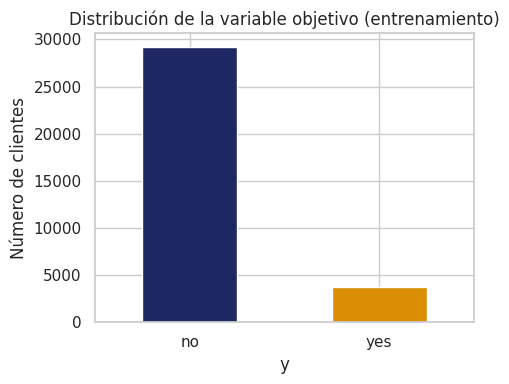

In [11]:
conteo = ent["y"].value_counts()
porcentaje = ent["y"].value_counts(normalize=True) * 100
razon = conteo["no"] / conteo["yes"]
exactitud_base = 100 * conteo["no"] / conteo.sum()

print("Conteo por clase:")
print(conteo)
print("\nPorcentaje por clase:")
print(porcentaje.round(2))
print(f"\nRazón clase mayoritaria / minoritaria: {razon:.2f} : 1")
print(f"Exactitud de responder siempre 'no': {exactitud_base:.2f}%")

fig, ax = plt.subplots(figsize=(5, 4))
conteo.plot(kind="bar", color=[COLORES_CLASE[c] for c in conteo.index], ax=ax)
ax.set_xlabel("y")
ax.set_ylabel("Número de clientes")
ax.set_title("Distribución de la variable objetivo (entrenamiento)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Tu observación.** La clase `no` representa 88.73% (29,238 clientes) y `yes` 11.27% (3,712 clientes), una razón de 7.88:1. La exactitud de responder siempre "no" sería 88.73%, justo lo que predije. Esto implica que la exactitud **no** es una métrica útil para evaluar el modelo: un clasificador trivial que ignora todas las características ya la supera por mucho. Conviene usar métricas sensibles a la clase minoritaria (precisión, recall, F1 o AUC-PR) y considerar alguna técnica de rebalanceo (pesos de clase, sobremuestreo o submuestreo) al entrenar.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** Espero que `duration` difiera más entre clases (las llamadas más largas suelen terminar en "sí"), seguida de los indicadores macroeconómicos (`emp.var.rate`, `euribor3m`, `nr.employed`), que reflejan el contexto de la campaña. Espero que `age`, `campaign`, `pdays` y `previous` cambien poco entre clases.

y                     no       yes
age               38.000    37.000
duration         164.000   448.000
campaign           2.000     2.000
pdays            999.000   999.000
previous           0.000     0.000
emp.var.rate       1.100    -1.800
cons.price.idx    93.918    93.200
cons.conf.idx    -41.800   -40.400
euribor3m          4.857     1.266
nr.employed     5195.800  5099.100


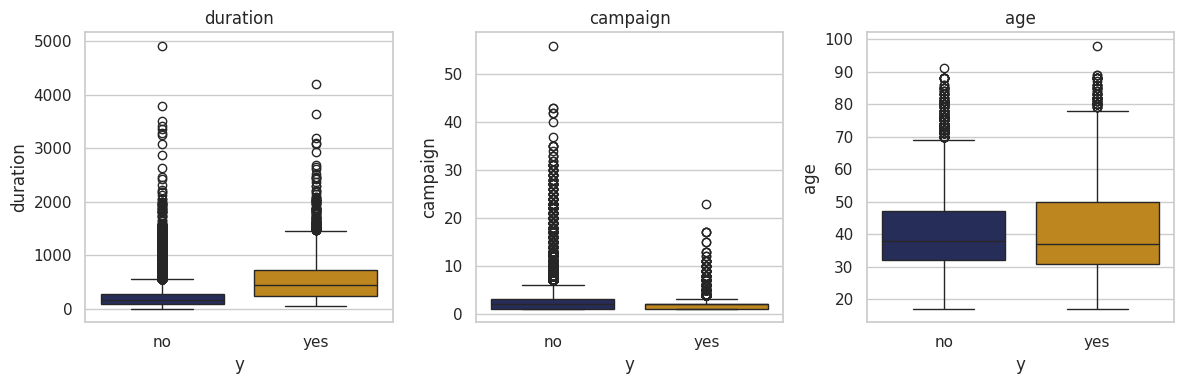

In [12]:
medianas = ent.groupby("y")[numericas].median().T
print(medianas)

variables_box = ["duration", "campaign", "age"]
fig, axes = plt.subplots(1, len(variables_box), figsize=(4 * len(variables_box), 4))
for ax, col in zip(axes, variables_box):
    sns.boxplot(data=ent, x="y", y=col, hue="y", palette=COLORES_CLASE, legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Tu observación.** Confirmando mi predicción, las variables que más separan las clases son:

- `duration`: mediana de 164 s en `no` vs. 448 s en `yes`, más del doble.
- `emp.var.rate`: 1.1 vs. -1.8.
- `euribor3m`: 4.857 vs. 1.266.
- `nr.employed`: 5,195.8 vs. 5,099.1.

Las que casi no separan las clases son `age` (38 vs. 37), `campaign` (2 vs. 2), `pdays` (999 vs. 999) y `previous` (0 vs. 0). Los tres indicadores macro que más separan junto con `duration` sugieren que la contratación está muy asociada al contexto económico (tasas bajas, periodos de contracción del empleo) además de a la propia llamada.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** Espero que `duration` y `campaign` tengan más registros atípicos por Tukey, al ser variables de conteo/tiempo con colas largas (algunas llamadas muy largas, algunos clientes contactados muchas veces).

In [13]:
resultados_tukey = []
for col in numericas:
    q1, q3 = ent[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    n_fuera = ((ent[col] < lim_inf) | (ent[col] > lim_sup)).sum()
    resultados_tukey.append({
        "variable": col,
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "registros_fuera": n_fuera,
        "pct_fuera": round(100 * n_fuera / len(ent), 2),
    })

tabla_tukey = pd.DataFrame(resultados_tukey).sort_values("registros_fuera", ascending=False)
print(tabla_tukey.to_string(index=False))

      variable  limite_inferior  limite_superior  registros_fuera  pct_fuera
      previous             0.00             0.00             4534      13.76
      duration          -221.00           643.00             2366       7.18
      campaign            -2.00             6.00             1916       5.81
         pdays           999.00           999.00             1226       3.72
           age             9.50            69.50              368       1.12
 cons.conf.idx           -52.15           -26.95              359       1.09
  emp.var.rate            -6.60             6.20                0       0.00
cons.price.idx            91.70            95.37                0       0.00
     euribor3m            -4.08            10.39                0       0.00
   nr.employed          4905.60          5421.60                0       0.00


**Tu respuesta.** Mi predicción se cumplió solo a medias: `duration` (2,366 fuera, 7.18%) y `campaign` (1,916, 5.81%) sí tienen muchos atípicos, pero `previous` (4,534, 13.76%) y `pdays` (1,226, 3.72%) tienen aún más, aunque por una razón distinta: su rango intercuartílico es 0 (al menos 75% de las filas vale exactamente 0 en `previous` o 999 en `pdays`), así que cualquier valor distinto de ese "techo" queda fuera de los límites de Tukey. No son atípicos reales sino la estructura binaria de "contactado antes / no contactado antes" de esas columnas.

Por variable:

- `duration`: no eliminaría esos registros en el EDA; son simplemente llamadas largas, válidas (de hecho la variable completa se descarta como característica más adelante, en la parte F2, por fuga de información, no por ser atípica).
- `campaign`: sí revisaría los valores más extremos (hasta 56 contactos); para un modelo sensible a la escala conviene transformar (ver D4) en vez de eliminar filas, para no perder observaciones, sobre todo de la clase minoritaria.
- `pdays` y `previous`: no son atípicos a eliminar, son artefactos de la codificación; lo adecuado es recodificarlos (por ejemplo, una bandera booleana "contactado antes") en preprocesamiento, no limpiarlos como atípicos.
- `age`: los 368 registros fuera de rango son clientes de mayor edad, válidos; no los eliminaría.
- `cons.conf.idx`: sus atípicos (359) corresponden a periodos específicos de la serie económica, no a errores; tampoco los eliminaría.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** Espero que `np.log1p` reduzca más la asimetría que la raíz cuadrada, porque es una transformación más fuerte y `campaign` tiene una cola muy larga (hasta 56 contactos).

          original  raiz_cuadrada  log1p
age          0.761          0.426  0.132
duration     3.327          1.204 -0.430
campaign     4.743          2.163  1.351


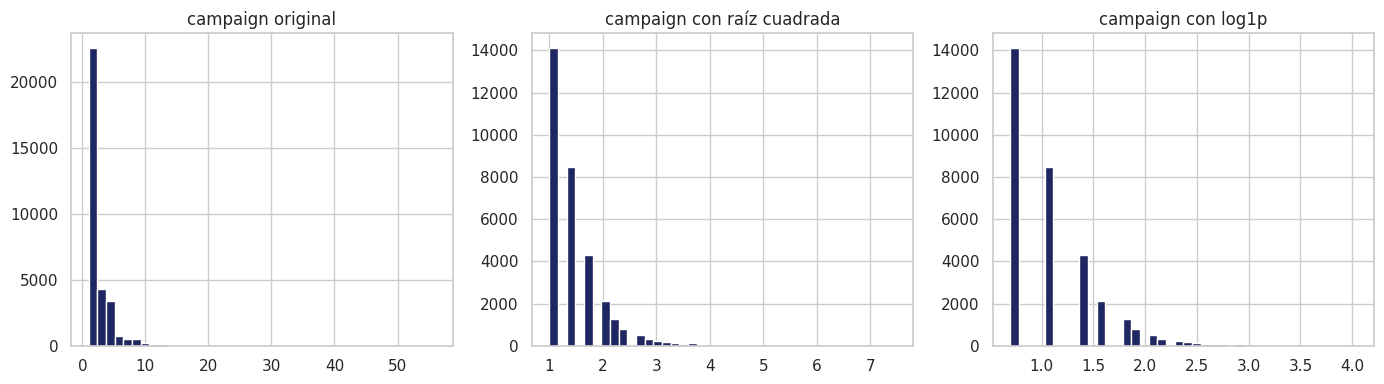

In [14]:
vars_asimetria = ["age", "duration", "campaign"]
tabla_asim = pd.DataFrame({
    "original": [ent[c].skew() for c in vars_asimetria],
    "raiz_cuadrada": [np.sqrt(ent[c].clip(lower=0)).skew() for c in vars_asimetria],
    "log1p": [np.log1p(ent[c]).skew() for c in vars_asimetria],
}, index=vars_asimetria).round(3)
print(tabla_asim)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(ent["campaign"], bins=40, color=AZUL)
axes[0].set_title("campaign original")
axes[1].hist(np.sqrt(ent["campaign"]), bins=40, color=AZUL)
axes[1].set_title("campaign con raíz cuadrada")
axes[2].hist(np.log1p(ent["campaign"]), bins=40, color=AZUL)
axes[2].set_title("campaign con log1p")
plt.tight_layout()
plt.show()

**Tu observación.** Las asimetrías fueron:

| Variable | Original | Raíz cuadrada | log1p |
| --- | --- | --- | --- |
| age | 0.761 | 0.426 | 0.132 |
| duration | 3.327 | 1.204 | -0.430 |
| campaign | 4.743 | 2.163 | 1.351 |

Para `campaign`, `log1p` redujo más la asimetría (1.351) que la raíz cuadrada (2.163), confirmando mi predicción. Para `age`, `log1p` también deja la distribución casi simétrica (0.132) y sería la transformación a usar. Para `duration`, `log1p` sobre-corrige y la deja con asimetría negativa de magnitud similar a la que tenía (-0.430), mientras que la raíz cuadrada (1.204) se queda más cerca de cero en valor absoluto comparado con el original (3.327) sin invertir el signo; ahí preferiría la raíz cuadrada. En los tres casos esto solo aplicaría si se usa un modelo sensible a la escala (regresión logística, SVM, red neuronal); con árboles de decisión no haría falta transformar.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** Espero que `poutcome` (categoría `success`) tenga la mayor tasa de contratación, porque un cliente que ya contrató en una campaña anterior es más propenso a volver a hacerlo. Espero que `housing` y `loan` casi no separen las clases, porque tener un crédito hipotecario o personal no parece muy relacionado con contratar un depósito a plazo.

In [15]:
print("Número de categorías por variable:")
for col in categoricas:
    print(f"  {col}: {ent[col].nunique()}")

tasa_global = ent["suscribe"].mean() * 100
print(f"\nTasa global de contratación en ent: {tasa_global:.2f}%")

Número de categorías por variable:
  job: 12
  marital: 4
  education: 8
  default: 3
  housing: 3
  loan: 3
  contact: 2
  month: 10
  day_of_week: 5
  poutcome: 3

Tasa global de contratación en ent: 11.27%


In [16]:
tablas = []
for col in categoricas:
    g = ent.groupby(col)["suscribe"].agg(["count", "mean"]).reset_index()
    g.columns = ["categoria", "n_clientes", "tasa_contratacion"]
    g["tasa_contratacion"] = (g["tasa_contratacion"] * 100).round(2)
    g["variable"] = col
    tablas.append(g)
tabla_categorias = pd.concat(tablas, ignore_index=True)

print("12 categorías con mayor tasa de contratación:")
print(tabla_categorias.sort_values("tasa_contratacion", ascending=False).head(12).to_string(index=False))

print("\n8 categorías con menor tasa de contratación:")
print(tabla_categorias.sort_values("tasa_contratacion").head(8).to_string(index=False))

for col in ["default", "housing", "loan", "day_of_week"]:
    print(f"\nTabla de {col}:")
    print(tabla_categorias[tabla_categorias["variable"] == col].to_string(index=False))

12 categorías con mayor tasa de contratación:
 categoria  n_clientes  tasa_contratacion  variable
   success        1105              64.89  poutcome
       dec         143              50.35     month
       mar         436              49.77     month
       sep         464              44.61     month
       oct         587              43.27     month
   student         711              30.52       job
   retired        1366              25.48       job
       apr        2085              20.48     month
illiterate          16              18.75 education
   unknown          65              16.92   marital
   unknown        1397              14.82 education
  cellular       20908              14.70   contact

8 categorías con menor tasa de contratación:
  categoria  n_clientes  tasa_contratacion  variable
        yes           3               0.00   default
    unknown        6940               5.20   default
  telephone       12042               5.30   contact
        may       11

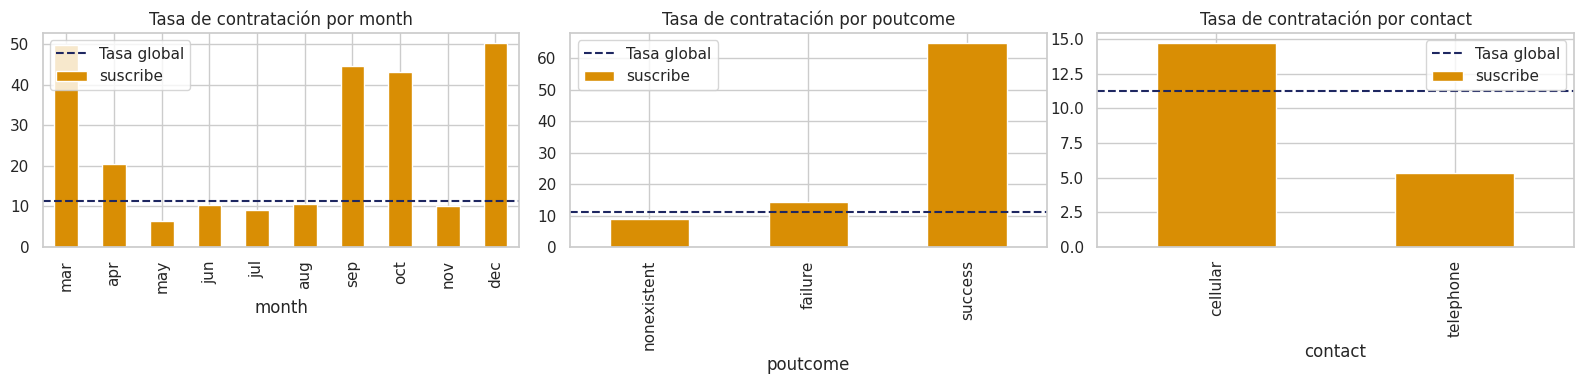

In [17]:
orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

tasa_mes = ent.groupby("month")["suscribe"].mean().reindex(orden_meses) * 100
tasa_mes.plot(kind="bar", color=NARANJA, ax=axes[0])
axes[0].axhline(tasa_global, color=AZUL, linestyle="--", label="Tasa global")
axes[0].set_title("Tasa de contratación por month")
axes[0].legend()

tasa_pout = ent.groupby("poutcome")["suscribe"].mean().sort_values() * 100
tasa_pout.plot(kind="bar", color=NARANJA, ax=axes[1])
axes[1].axhline(tasa_global, color=AZUL, linestyle="--", label="Tasa global")
axes[1].set_title("Tasa de contratación por poutcome")
axes[1].legend()

tasa_contact = ent.groupby("contact")["suscribe"].mean() * 100
tasa_contact.plot(kind="bar", color=NARANJA, ax=axes[2])
axes[2].axhline(tasa_global, color=AZUL, linestyle="--", label="Tasa global")
axes[2].set_title("Tasa de contratación por contact")
axes[2].legend()

plt.tight_layout()
plt.show()

**Tu observación.** Mi predicción se confirmó: `poutcome == "success"` tiene la mayor tasa (64.89%, n=1,105). También destacan diciembre (50.35%, n=143), marzo (49.77%, n=436), septiembre (44.61%, n=464) y octubre (43.27%, n=587) en `month`, aunque son meses con pocos contactos, así que esas tasas altas hay que leerlas con cautela (pueden ser ruido de muestra pequeña, o reflejar campañas específicas y más dirigidas en esos meses). También destacan `student` (30.52%, n=711) y `retired` (25.48%, n=1,366) en `job`.

Las tasas más bajas son `default == "yes"` (0%, pero solo 3 filas, no confiable), `default == "unknown"` (5.20%, n=6,940), `contact == "telephone"` (5.30%, n=12,042), `month == "may"` (6.35%, el mes con más contactos, n=11,011), `job == "blue-collar"` (6.92%, n=7,441), `education == "basic.9y"` (7.65%) y `job == "services"` (7.95%).

Las variables que casi no separan las clases son `housing` (10.93% a 11.56%, todas cerca de la tasa global de 11.27%) y `loan` (11.23% a 11.31%), como predije; `day_of_week` también varía poco (10.25% a 12.00%).

**Tu respuesta.** La categoría `unknown` de `default` tiene una tasa de contratación de 5.20%, muy por debajo del 12.88% de la categoría `no`. Esa diferencia sugiere que `unknown` no es aleatorio (no es "missing completamente al azar"): probablemente corresponde a un perfil distinto de cliente (quizá con menor relación o antigüedad con el banco), que además contrata menos. Esto refuerza la decisión de tratar `unknown` como categoría propia en vez de imputarla con la moda (`no`), porque imputarla borraría justo esa señal.

Con `yes` de `default` (solo 3 filas) e `illiterate` de `education` (16 filas) hay que cuidar que sus tasas (0% y 18.75% respectivamente) están calculadas con muy pocos registros, por lo que no son confiables y un modelo podría sobreajustarse a ellas. Conviene agruparlas con una categoría cercana (por ejemplo, `illiterate` dentro de una categoría "básica/otro", o fusionar `yes`+`unknown` en `default`) antes de codificar.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** Espero que `emp.var.rate` y `euribor3m` estén muy correlacionados, porque ambos reflejan el ciclo económico y las tasas de interés; también espero una correlación considerable entre `emp.var.rate` y `cons.price.idx`.

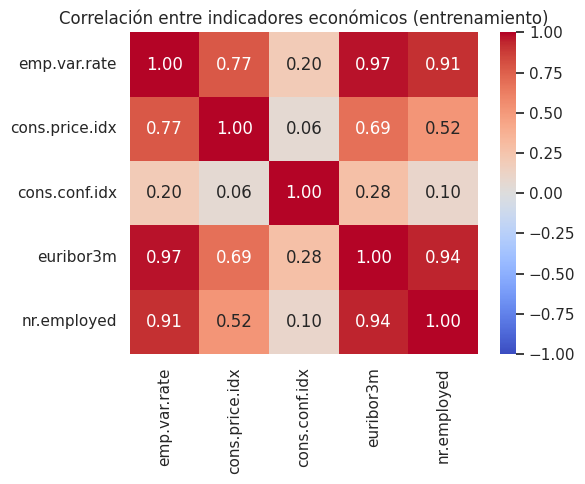

In [18]:
corr_macro = ent[macro].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_macro, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre indicadores económicos (entrenamiento)")
plt.tight_layout()
plt.show()

**Tu observación.** Los pares más correlacionados son `emp.var.rate`-`euribor3m` (r=0.97), `euribor3m`-`nr.employed` (r=0.95) y `emp.var.rate`-`nr.employed` (r=0.91): tres variables casi redundantes entre sí, confirmando mi predicción. `emp.var.rate`-`cons.price.idx` también está alta (r=0.77). `cons.conf.idx` es la más independiente, con correlaciones máximas de apenas 0.28. Esto implica que, para un modelo lineal, conviene conservar solo una o dos de {`emp.var.rate`, `euribor3m`, `nr.employed`} (o aplicar PCA/regularización) para evitar colinealidad severa; para modelos de árboles la redundancia es menos crítica, pero las variables adicionales igual no aportarían información nueva.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [19]:
print(ent.groupby("y")["duration"].describe())

       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** No la incluiría como característica de un modelo que decida a quién llamar. Por definición, `duration` es la duración de la llamada que ya se hizo, así que su valor no existe todavía en el momento de decidir a quién contactar: usarla sería fuga de información hacia el futuro. Lo observado lo confirma: la mediana de `duration` en `yes` (448 s) más que duplica la de `no` (164 s), y el mínimo en `yes` es 63 s mientras que en `no` puede ser 0; la variable casi determina el resultado porque está midiendo, indirectamente, si la conversación avanzó lo suficiente para cerrar la venta. Sería útil solo para un modelo que opere durante la llamada (por ejemplo, para decidir cuándo colgar), no para priorizar a quién contactar.

**Tu respuesta.** Como el conjunto está ordenado por fecha (mayo 2008 a noviembre 2010) y los indicadores macro (`emp.var.rate`, `euribor3m`, etc.) varían con el tiempo, una división completamente aleatoria como la de la parte C mezcla periodos económicos entre entrenamiento y prueba: el modelo "ve" en entrenamiento combinaciones de indicadores que en la realidad ocurrieron después de algunas de las filas de prueba. Esto hace la evaluación demasiado optimista, porque en producción el modelo tendría que predecir sobre campañas futuras, con indicadores económicos que todavía no existen al momento de entrenar. Una evaluación más realista usaría una división temporal (entrenar con los periodos más antiguos y evaluar con los más recientes) o validación cruzada por bloques de tiempo.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| `duration` separa fuertemente las clases (mediana 448 s en `yes` vs. 164 s en `no`), pero su valor solo existe después de la llamada. | Excluir `duration` como característica del modelo operativo. | Preprocesamiento (selección de características) |
| `unknown` representa 20.87% de `default`, 4.20% de `education`, 2.40% de `housing` y `loan`, 0.80% de `job` y 0.19% de `marital`; 0 `NaN` reales. | Tratar `unknown` como categoría propia en cada variable categórica, sin imputar ni eliminar filas. | Preprocesamiento (codificación de categóricas) |
| `pdays == 999` en 96.32% de las filas y 4,110 filas de `poutcome == "failure"` también tienen `pdays == 999` pese a tener contacto previo (inconsistencia de codificación). | Recodificar `pdays`/`previous` en una bandera binaria "contactado antes" en vez de usar los valores numéricos crudos. | Preprocesamiento (ingeniería de características) |
| Desbalance de clases de 7.88:1 (88.73% `no` vs. 11.27% `yes`); un modelo trivial que siempre responde "no" ya logra 88.73% de exactitud. | Usar métricas sensibles a la clase minoritaria (recall, F1, AUC-PR) y aplicar rebalanceo (pesos de clase o sobremuestreo) al entrenar. | Modelos y evaluación |
| `emp.var.rate`, `euribor3m` y `nr.employed` están muy correlacionados entre sí (r=0.97, r=0.95, r=0.91). | Para modelos lineales, conservar solo uno o dos de estos indicadores o aplicar regularización/PCA; para árboles, dejarlos sin esperar que aporten información independiente. | Preprocesamiento y modelos |
| `campaign` tiene asimetría de 4.74 (la más alta de las tres evaluadas) y `log1p` la reduce a 1.35, más que la raíz cuadrada (2.16). | Aplicar `log1p` a `campaign` si se usa un modelo sensible a la escala; no transformar si se usa un modelo de árboles. | Preprocesamiento |
| `default == "yes"` solo tiene 3 filas y `education == "illiterate"` solo 16; sus tasas de contratación no son confiables. | Agrupar estas categorías raras con una categoría cercana antes de codificar, para evitar sobreajuste. | Preprocesamiento |
| 12 filas completamente duplicadas (0.03% del conjunto). | Eliminarlas antes de entrenar, porque no aportan información nueva y podrían sesgar ligeramente la división entrenamiento/prueba si coincidieran en ambos conjuntos. | Preprocesamiento |

### G2. Uso de los datos

**Tu respuesta.** Con el conjunto total `df` se hizo toda la parte B (estructura, `NaN`, `unknown`, duplicados, consistencia `pdays`/`poutcome`, rangos de dominio), porque son verificaciones estructurales y de calidad que no usan la variable objetivo ni calculan ningún parámetro que luego se aplicaría al modelo; no dependen de una partición y por eso es seguro hacerlas sobre todos los datos. A partir de la parte C (división entrenamiento/prueba), todo lo demás —distribución del objetivo, medianas y cajas por clase, límites de Tukey, asimetría, tasas de contratación por categoría, correlaciones entre indicadores y el análisis de `duration`— se hizo solo con `ent` (entrenamiento), porque relaciona características con la variable objetivo y produce estadísticos (cuartiles para Tukey, tasas por categoría, correlaciones) que después fundamentan decisiones de preprocesamiento y modelado; calcularlos con el conjunto completo filtraría información de prueba hacia esas decisiones.

**Tu respuesta.** Por ejemplo, los límites de Tukey de la parte D3 o la lista de categorías raras a agrupar de la parte G1 podrían ajustarse para parecerse más a los atípicos o categorías específicas de prueba, en vez de generalizar solo a partir de entrenamiento; también la elección de qué transformación aplicar en D4 podría "optimizarse" viendo cómo queda la asimetría en el conjunto completo. Si eso ocurriera, la evaluación final en `prueba` dejaría de medir honestamente el desempeño en datos nuevos: las decisiones de preprocesamiento ya habrían "visto" indirectamente la estructura de prueba, y las métricas de evaluación (exactitud, F1, AUC-PR) resultarían optimistas respecto al desempeño real que tendría el modelo en producción.